# Hybrid search: optimized BM25 + GTE-small

Do complementary query-level strengths translate into better retrieval when we combine results?
Compare **optimized BM25**, **GTE-small**, and **equal-weight Reciprocal Rank Fusion (RRF)**
on Quora, WANDS and HotpotQA.

$$s_{RRF}(d)=\frac{1}{60+rank_{BM25}(d)}+\frac{1}{60+rank_{GTE}(d)}.$$

Ranks start at 1; a document absent from a list contributes zero for that list. Fuse the two top-100
lists and keep the best 100 distinct documents. RRF combines ranks, so it needs no normalization
between BM25 scores and cosine similarities. **60 is fixed before evaluation**, with no search over
fusion weights or constants on these queries. This tests one simple hybrid, not the best possible hybrid.

- **Quora / HotpotQA:** reuse dev-selected BM25 settings and evaluate on test.
- **WANDS:** reuse each saved fold's parameter choice and average five OOF runs. The earlier field
  weights were chosen using the same queries, so this remains a **conditional** evaluation.
- GTE uses three WANDS fields; BM25 uses five. The hybrid combines these existing systems, not two
  systems with identical input text. WANDS uses graded nDCG and Exact-only MRR; BEIR uses binary labels.

**Not executed.** Saved GTE rankings are reused; BM25 rankings must be rebuilt because its earlier
export contains metrics, not document rankings. HotpotQA still requires substantial RAM and time.
Results stay in memory; exporting is optional. No new GTE encoding or model download is needed.

## 1. Inputs and frozen settings

Set `GTE_ROOT` to the downloaded `bm25_gte_results` directory and `BM25_ROOT` to the weighted tuning
export. Each contains dataset subfolders. WANDS data must be local; missing BEIR data is downloaded
only when the notebook is run. Corpus row order must match the saved dense run: rankings store row
numbers, not document IDs. The checks below verify judged relevance against saved per-query scores,
but cannot prove identity of unjudged rows. Use the same corpus files/order as the original runs.


In [17]:
# Install in the active kernel if needed:
# %pip install "bm25s==0.3.16" numpy pandas nltk datasets pyarrow tqdm matplotlib
from pathlib import Path
from array import array
from functools import lru_cache
from zipfile import ZipFile
from importlib.metadata import version
import gc, json, re
import numpy as np
import pandas as pd
import bm25s
from datasets import Dataset, load_dataset
from nltk.stem import PorterStemmer
from tqdm.auto import tqdm
from IPython.display import display

ROOT = None  # Or Path('/path/to/e2e-search-lab').
if ROOT is None:
    ROOT = next((p for p in [Path.cwd(), Path.cwd().parent]
                 if (p/'datasets').is_dir() or (p/'datasets.zip').is_file()), Path.cwd())
ROOT = Path(ROOT).expanduser().resolve()
DATASETS = ['quora', 'wands', 'hotpotqa']
BM25_ROOT = ROOT/'results/bm25_parameter_tuning_weighted'
GTE_ROOT = Path.home()/'Downloads/bm25_gte_results'  # Change if stored elsewhere.
K, CHUNK, RRF_C = 100, 4096, 60
METRICS = ['nDCG@10', 'MRR@10', 'Recall@10', 'Recall@100']
PACKAGES = {p: version(p) for p in ['bm25s', 'numpy', 'pandas', 'nltk', 'datasets']}
BM25_MANIFESTS = {name: json.loads((BM25_ROOT/name/'manifest.json').read_text()) for name in DATASETS}
FIELD_WEIGHTS = {name: m['field_weights'] for name,m in BM25_MANIFESTS.items()}
for name, manifest in BM25_MANIFESTS.items():
    assert manifest['method'] == 'lucene' and manifest['k'] == K
    assert all(w > 0 for w in FIELD_WEIGHTS[name].values())
    assert set(manifest['fields']) == set(FIELD_WEIGHTS[name])
    if manifest['packages'] != {p: PACKAGES[p] for p in manifest['packages']}:
        print(name, 'package versions differ; saved-score checks below must still pass.')
print('Frozen weights:', FIELD_WEIGHTS)


Frozen weights: {'quora': {'text': 1.0}, 'wands': {'product_name': 1.0, 'category hierarchy': 0.5, 'product_description': 0.25, 'product_class': 0.25, 'product_features': 0.25}, 'hotpotqa': {'title': 0.5, 'text': 1.0}}


## 2. Load the same queries, judgments and corpus

Keep the full corpus. BEIR self-matches are excluded; queries without a positive judgment are omitted.
Saved query IDs are checked before scoring and matched by ID, never by CSV row position.


In [18]:
def load_beir(name):
    folder = ROOT/'datasets'/name
    if (folder/'corpus.parquet').exists():
        corpus = Dataset.from_parquet(str(folder/'corpus.parquet'))
        queries = pd.read_parquet(folder/'queries.parquet')
        rels = {s: pd.read_parquet(folder/f'qrels_{s}.parquet') for s in ['dev','test']}
    else:
        corpus = load_dataset(f'BeIR/{name}', 'corpus', split='corpus')
        queries = load_dataset(f'BeIR/{name}', 'queries', split='queries').to_pandas()
        rels = {s: pd.read_csv(f'https://huggingface.co/datasets/BeIR/{name}-qrels/resolve/main/{s}.tsv',
                              sep='\t', dtype={'query-id': str, 'corpus-id': str}) for s in ['dev','test']}
    query_map = dict(zip(queries['_id'].astype(str), queries['text'].fillna('').astype(str)))
    splits = {}
    for split, rel in rels.items():
        assert rel['score'].notna().all()
        rel['query-id'], rel['corpus-id'] = rel['query-id'].astype(str), rel['corpus-id'].astype(str)
        rel = rel.groupby(['query-id','corpus-id'], as_index=False)['score'].max()
        qrels = {q: dict(zip(g['corpus-id'], g['score'].astype(int))) for q,g in rel.groupby('query-id', sort=False)}
        qids = [q for q,g in qrels.items() if any(v > 0 for v in g.values())]
        assert qids and set(qids) <= query_map.keys()
        splits[split] = {'qids': qids, 'qrels': qrels}
    assert set(splits['dev']['qids']).isdisjoint(splits['test']['qids']), 'Dev/test query overlap.'
    needed = {d for s in splits.values() for q in s['qids'] for d in s['qrels'][q]}
    needed.update(q for s in splits.values() for q in s['qids'])
    positions = {}
    for start in range(0, len(corpus), CHUNK):
        for offset, doc in enumerate(corpus[start:start+CHUNK]['_id']):
            doc = str(doc)
            if doc in needed:
                assert doc not in positions, 'Duplicate corpus ID.'
                positions[doc] = start+offset
    for data in splits.values():
        assert all(d in positions for q in data['qids'] for d,v in data['qrels'][q].items() if v > 0)
        data['grades'] = [{positions[d]:v for d,v in data['qrels'][q].items() if d in positions} for q in data['qids']]
        data['queries'] = [query_map[q] for q in data['qids']]
        data['excluded'] = [positions.get(q,-1) for q in data['qids']]
        del data['qrels']
    return corpus, splits

def load_data(name):
    if name != 'wands':
        corpus, splits = load_beir(name)
        return corpus, splits, list(FIELD_WEIGHTS[name]), False
    def table(filename):
        path = ROOT/'datasets/wands'/filename
        if path.exists():
            return pd.read_csv(path, sep='\t')
        with ZipFile(ROOT/'datasets.zip') as z, z.open(f'datasets/wands/{filename}') as f:
            return pd.read_csv(f, sep='\t')
    docs, queries, rel = [table(f'{s}.csv') for s in ['product', 'query', 'label']]
    fields = list(FIELD_WEIGHTS[name])
    assert docs.product_id.is_unique and queries.query_id.is_unique
    docs[fields] = docs[fields].fillna('').astype(str)
    corpus = Dataset.from_pandas(docs[fields].assign(_id=docs.product_id.astype(str)), preserve_index=False)
    positions = {str(d): i for i, d in enumerate(docs.product_id)}
    rel = rel.assign(qid=rel.query_id.astype(str), doc=rel.product_id.astype(str).map(positions),
                     grade=rel.label.map({'Exact': 2, 'Partial': 1, 'Irrelevant': 0}))
    assert rel[['doc', 'grade']].notna().all().all()
    rel = rel.groupby(['qid', 'doc'], as_index=False).grade.max()
    grades = {q: dict(zip(g.doc.astype(int), g.grade.astype(int))) for q, g in rel.groupby('qid')}
    query_map = dict(zip(queries.query_id.astype(str), queries['query'].fillna('').astype(str)))
    qids = [q for q, g in grades.items() if any(v > 0 for v in g.values())]
    assert len(qids) >= 4 and set(qids) <= query_map.keys()
    data = {'qids': qids, 'queries': [query_map[q] for q in qids],
            'grades': [grades[q] for q in qids], 'excluded': [-1]*len(qids)}
    return corpus, {'all': data}, fields, True


## 3. Rebuild optimized BM25 rankings

Each field has its own index; its raw BM25 score is multiplied by its frozen weight.
The saved parameter pair applies to every field. Only one parameter setting's indexes are held at a time.
BM25 returns positive-score documents only. Cutoff ties use corpus row order.


In [19]:
porter = PorterStemmer()

@lru_cache(maxsize=200_000)
def stem(word):
    return porter.stem(word)


def tokenize(text):
    return [stem(t) for t in re.findall(r'\w+', text.lower())]


def corpus_tokens(corpus, fields):
    vocab, ids = {}, []
    for start in tqdm(range(0, len(corpus), CHUNK), desc='Tokenizing corpus'):
        batch = corpus[start:start+CHUNK]
        for row in zip(*(batch[f] for f in fields)):
            text = ' '.join(str(v or '') for v in row)
            ids.append(array('I', (vocab.setdefault(t, len(vocab)) for t in tokenize(text))))
    assert vocab
    stem.cache_clear()
    return bm25s.tokenization.Tokenized(ids, vocab)


def build(tokens, params):
    models = {}
    for field, field_tokens in tokens.items():
        index = bm25s.BM25(method='lucene', k1=params[0], b=params[1])
        index.index(field_tokens, show_progress=True)
        models[field] = index
    return models


def topk(scores):
    valid = np.flatnonzero(np.isfinite(scores) & (scores > 0))
    k = min(K, len(valid))
    if not k:
        return np.array([], dtype=int)
    cutoff = np.partition(scores[valid], len(valid)-k)[len(valid)-k]
    above = valid[scores[valid] > cutoff]
    tied = valid[scores[valid] == cutoff][:k-len(above)]
    ids = np.concatenate([above, tied])
    return ids[np.lexsort((ids, -scores[ids]))]


def retrieve(models, data, weights, n_docs):
    ranked = np.full((len(data['qids']), K), -1, dtype=np.int32)
    for qi, text in enumerate(tqdm(data['queries'], desc='Optimized BM25')):
        scores = np.zeros(n_docs, dtype=np.float32)
        tokens = tokenize(text)
        for field, index in models.items():
            known = [t for t in tokens if t in index.vocab_dict]
            if known:
                scores += weights[field]*index.get_scores(known)
        if data['excluded'][qi] >= 0:
            scores[data['excluded'][qi]] = -np.inf
        ids = topk(scores)
        ranked[qi, :len(ids)] = ids
    return ranked


## 4. Fuse ranks and validate cached results

All three systems use the same metrics and judgments. The saved GTE and optimized BM25 per-query
metrics must reproduce before hybrid results are reported. A mismatch stops the comparison rather
than silently combining incompatible runs. Fusion never uses relevance judgments.


In [20]:
def evaluate(ranked, data, graded):
    values = np.zeros((len(ranked), len(METRICS)))
    discounts = 1/np.log2(np.arange(2, 12))
    for qi, row in enumerate(ranked):
        ids = row[row >= 0]
        grades = data['grades'][qi]
        g = np.array([grades.get(int(d), 0) for d in ids])
        ideal = np.array(sorted(grades.values(), reverse=True)[:10])
        gain = lambda x: 2.0**x-1 if graded else (x > 0).astype(float)
        idcg = np.dot(gain(ideal), discounts[:len(ideal)])
        ndcg = np.dot(gain(g[:10]), discounts[:min(10, len(g))])/idcg
        exact = 2 if graded else 1
        hits = np.flatnonzero(g[:10] >= exact)
        rr = 1/(hits[0]+1) if len(hits) else 0.0
        if graded and not any(v == 2 for v in grades.values()):
            rr = np.nan
        nrel = sum(v > 0 for v in grades.values())
        values[qi] = [ndcg, rr, (g[:10] > 0).sum()/nrel, (g > 0).sum()/nrel]
    return values

def rrf(bm25, gte):
    assert bm25.shape == gte.shape
    fused = np.full_like(bm25, -1)
    for qi, (left, right) in enumerate(zip(bm25, gte)):
        scores = {}
        for row in (left, right):
            for rank, doc in enumerate(row, 1):
                if doc >= 0:
                    scores[int(doc)] = scores.get(int(doc), 0.0) + 1/(RRF_C+rank)
        ids = sorted(scores, key=lambda d: (-scores[d], d))[:K]
        fused[qi, :len(ids)] = ids
    return fused


def validate_rankings(ranked, data, n_docs):
    assert ranked.shape == (len(data['qids']), K)
    assert np.issubdtype(ranked.dtype, np.integer)
    assert ((ranked >= -1) & (ranked < n_docs)).all()
    for row, excluded in zip(ranked, data['excluded']):
        valid = row[row >= 0]
        assert len(valid) == len(set(valid))
        assert excluded < 0 or excluded not in valid


def check_saved(values, saved, qids):
    assert not saved.query_id.duplicated().any()
    assert set(saved.query_id) == set(qids), 'Saved query set differs.'
    reference = saved.set_index('query_id').loc[qids, METRICS].to_numpy(float)
    assert np.allclose(values, reference, atol=1e-7, rtol=0, equal_nan=True), (
        'Metrics differ from the saved run. Check corpus row order, tokenizer, settings and labels.')


def means(values):
    return {m: float(np.nanmean(values[:, i])) if np.isfinite(values[:, i]).any() else np.nan
            for i,m in enumerate(METRICS)}


## 5. Standalone systems versus hybrid

For WANDS, reconstruct the exact saved query folds and fuse each query's held-out BM25 ranking with
its GTE ranking. Average **metrics** over seeds; averaging ranked document IDs would be meaningless.
The fusion rule stays fixed across all datasets and folds. A gain is not guaranteed: RRF can promote
documents agreed on by both systems, but can also displace a strong result found by just one.


In [21]:
results, all_rows = {}, []
for name in DATASETS:
    corpus, splits, fields, graded = load_data(name)
    split = 'all' if graded else 'test'
    data = splits[split]
    manifest = BM25_MANIFESTS[name]
    assert len(corpus) == manifest['corpus_rows']
    # Exact order matters for reconstructing the previous parameter-selection folds.
    assert data['qids'] == manifest['query_ids'][split], 'BM25 query order changed.'
    dense_folder = GTE_ROOT/name/split
    dense_meta = json.loads((dense_folder/'manifest.json').read_text())
    assert dense_meta['model'] == 'thenlper/gte-small' and dense_meta['k'] == K
    assert dense_meta['corpus_rows'] == len(corpus)
    assert len(set(dense_meta['query_ids'])) == len(dense_meta['query_ids'])
    assert set(dense_meta['query_ids']) == set(data['qids'])
    dense_positions = {q: i for i,q in enumerate(dense_meta['query_ids'])}
    with np.load(dense_folder/'rankings.npz') as saved:
        gte = saved['gte'][[dense_positions[q] for q in data['qids']]].copy()
    validate_rankings(gte, data, len(corpus))
    gte_values = evaluate(gte, data, graded)
    dense_metrics = pd.read_csv(dense_folder/'per_query.csv', dtype={'query_id': str})
    check_saved(gte_values, dense_metrics[dense_metrics.method == 'GTE-small'], data['qids'])
    choices = pd.read_csv(BM25_ROOT/name/'selected_parameters.csv')
    if graded:
        seeds = manifest['seeds']
        assert not choices.duplicated(['seed', 'held_fold']).any()
        assert set(zip(choices.seed, choices.held_fold)) == {(s,f) for s in seeds for f in (0,1)}
        params = sorted(set(zip(choices.k1, choices.b)))
    else:
        params = [tuple(manifest['selected'])]
    print(name, '| BM25 settings:', params, '| queries:', len(data['qids']))
    tokens = {f: corpus_tokens(corpus, [f]) for f in fields}
    bm25_rankings = {}
    for pair in params:
        models = build(tokens, pair)
        bm25_rankings[pair] = retrieve(models, data, FIELD_WEIGHTS[name], len(corpus))
        validate_rankings(bm25_rankings[pair], data, len(corpus))
        del models
        gc.collect()
    del tokens
    gc.collect()
    bm_runs, hybrid_runs, seed_rows = [], [], []
    for seed in (seeds if graded else [None]):
        if graded:
            folds = np.array_split(np.random.default_rng(seed).permutation(len(data['qids'])), 2)
            bm25 = np.full_like(gte, -1)
            for held_fold, held in enumerate(folds):
                choice = choices[(choices.seed == seed) & (choices.held_fold == held_fold)].iloc[0]
                bm25[held] = bm25_rankings[(float(choice.k1), float(choice.b))][held]
        else:
            bm25 = bm25_rankings[params[0]]
        hybrid = rrf(bm25, gte)
        bm_values, hybrid_values = evaluate(bm25, data, graded), evaluate(hybrid, data, graded)
        bm_runs.append(bm_values)
        hybrid_runs.append(hybrid_values)
        for method, values in [('Optimized BM25', bm_values), ('GTE-small', gte_values), ('Hybrid RRF', hybrid_values)]:
            seed_rows.append({'seed': seed, 'method': method, **means(values)})
    evaluated = {'Optimized BM25': np.mean(bm_runs, axis=0), 'GTE-small': gte_values,
                 'Hybrid RRF': np.mean(hybrid_runs, axis=0)}
    saved_metrics = pd.read_csv(BM25_ROOT/name/'per_query.csv', dtype={'query_id': str})
    saved_tuned = saved_metrics[saved_metrics.method.str.contains('tuned parameters|dev-selected parameters', regex=True)]
    check_saved(evaluated['Optimized BM25'], saved_tuned, data['qids'])
    rows, per_query = [], []
    for method, values in evaluated.items():
        rows.append({'dataset': name, 'evaluation': 'conditional OOF' if graded else 'test',
                     'method': method, **means(values)})
        for qi, qid in enumerate(data['qids']):
            per_query.append({'method': method, 'query_id': qid, **dict(zip(METRICS, values[qi]))})
    comparison = []
    for reference in ['Optimized BM25', 'GTE-small']:
        delta = evaluated['Hybrid RRF'][:, 0]-evaluated[reference][:, 0]
        comparison.append({'reference': reference, 'delta_nDCG_pp': 100*delta.mean(),
                           'wins': int((delta > 1e-10).sum()), 'ties': int((abs(delta) <= 1e-10).sum()),
                           'losses': int((delta < -1e-10).sum())})
    results[name] = {'summary': pd.DataFrame(rows), 'per_query': pd.DataFrame(per_query),
                     'by_seed': pd.DataFrame(seed_rows), 'hybrid_changes': pd.DataFrame(comparison),
                     'manifest': {'bm25_source': manifest, 'gte_source': dense_meta, 'packages': PACKAGES,
                                  'fusion': 'equal-weight RRF', 'rrf_c': RRF_C, 'input_depth': K,
                                  'output_depth': K, 'fusion_tuned': False}}
    display(results[name]['summary'].round(4))
    display(results[name]['hybrid_changes'].round(3))
    all_rows.extend(rows)
    del corpus, bm25_rankings, bm25, hybrid, gte
    stem.cache_clear()
    gc.collect()
summary = pd.DataFrame(all_rows)
display(summary.round(4))


quora | BM25 settings: [(0.6, 1.0)] | queries: 10000


Optimized BM25: 100%|██████████| 10000/10000 [00:34<00:00, 291.72it/s]           


,dataset,evaluation,method,nDCG@10,MRR@10,Recall@10,Recall@100
0,quora,test,Optimized BM25,0.8011,0.7955,0.8978,0.9744
1,quora,test,GTE-small,0.8802,0.8725,0.9540,0.9955
2,quora,test,Hybrid RRF,0.8662,0.8619,0.9439,0.9952


,reference,delta_nDCG_pp,wins,ties,losses
0,Optimized BM25,6.509,2751,6827,422
1,GTE-small,-1.397,1246,7183,1571


wands | BM25 settings: [(0.6, 0.0), (0.6, 0.75)] | queries: 479


Optimized BM25: 100%|██████████| 479/479 [00:00<00:00, 5004.76it/s]            


... (3 outputs left out)

Optimized BM25: 100%|██████████| 7405/7405 [07:31<00:00, 16.39it/s]                


,dataset,evaluation,method,nDCG@10,MRR@10,Recall@10,Recall@100
0,hotpotqa,test,Optimized BM25,0.6323,0.8049,0.6521,0.7772
1,hotpotqa,test,GTE-small,0.6378,0.8008,0.6580,0.7758
2,hotpotqa,test,Hybrid RRF,0.6811,0.8398,0.7084,0.8203


,reference,delta_nDCG_pp,wins,ties,losses
0,Optimized BM25,4.883,2527,3851,1027
1,GTE-small,4.328,2343,3904,1158


,dataset,evaluation,method,nDCG@10,MRR@10,Recall@10,Recall@100
0,quora,test,Optimized BM25,0.8011,0.7955,0.8978,0.9744
1,quora,test,GTE-small,0.8802,0.8725,0.9540,0.9955
2,quora,test,Hybrid RRF,0.8662,0.8619,0.9439,0.9952
3,wands,conditional OOF,Optimized BM25,0.7269,0.7033,0.0653,0.4172
4,wands,conditional OOF,GTE-small,0.7174,0.7147,0.0609,0.3801
5,wands,conditional OOF,Hybrid RRF,0.7622,0.7324,0.0656,0.4188
6,hotpotqa,test,Optimized BM25,0.6323,0.8049,0.6521,0.7772
7,hotpotqa,test,GTE-small,0.6378,0.8008,0.6580,0.7758
8,hotpotqa,test,Hybrid RRF,0.6811,0.8398,0.7084,0.8203


## Optional export

Tables stay in `results` and `summary`. The function below writes only when explicitly called;
leave the last line commented to avoid saving result files. Data-library download caches are separate.


In [22]:
def save_results(folder):
    folder = Path(folder).expanduser()
    folder.mkdir(parents=True, exist_ok=True)
    summary.to_csv(folder/'summary.csv', index=False)
    for name, tables in results.items():
        target = folder/name
        target.mkdir(parents=True, exist_ok=True)
        for key, value in tables.items():
            if key == 'manifest':
                (target/'manifest.json').write_text(json.dumps(value, indent=2))
            else:
                value.to_csv(target/f'{key}.csv', index=False)

# save_results(ROOT/'results/hybrid_bm25_gte')


## Does the combination help?

Compare all three methods within each dataset. nDCG measures ranking quality; Recall@100 measures
coverage for a possible reranker. Read the wins/losses tables alongside averages. Error bars are omitted:
five overlapping WANDS splits are not independent test sets. RRF only sees the union of two top-100
lists (at most 200 candidates), so it cannot recover documents absent from both. Larger retrieval depths,
weighted fusion and score normalization are separate experiments.


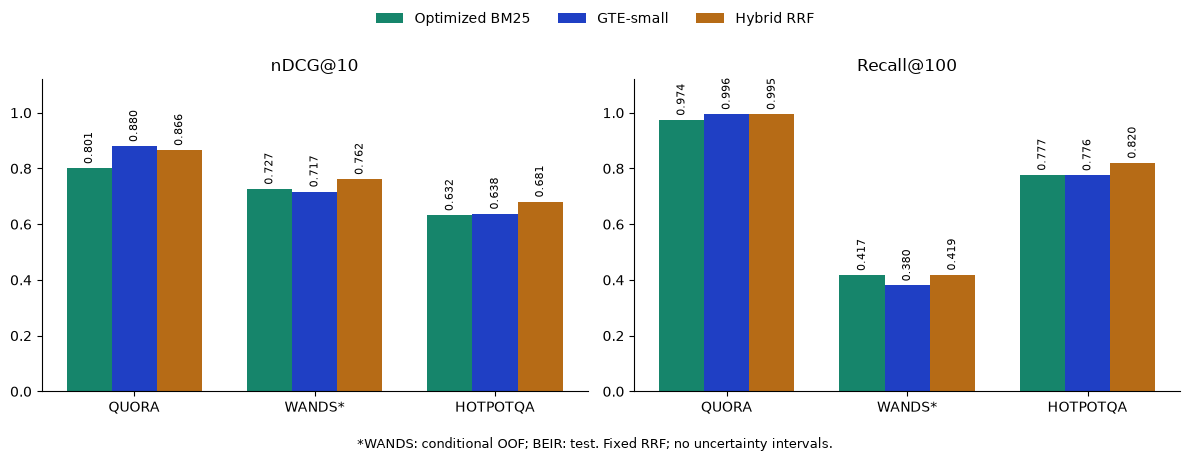

In [23]:
import matplotlib.pyplot as plt

methods = ['Optimized BM25', 'GTE-small', 'Hybrid RRF']
colors = ['#16856b', '#1f3fc4', '#b66b16']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric in zip(axes, ['nDCG@10', 'Recall@100']):
    table = summary.pivot(index='dataset', columns='method', values=metric).reindex(DATASETS)
    x, width = np.arange(len(table)), 0.25
    for i, (method, color) in enumerate(zip(methods, colors)):
        bars = ax.bar(x+(i-1)*width, table[method], width, label=method, color=color)
        ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8, rotation=90)
    ax.set_xticks(x, [f'{n.upper()}*' if n == 'wands' else n.upper() for n in table.index])
    ax.set(title=metric, ylim=(0, 1.12))
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.spines[['top', 'right']].set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
fig.text(0.5, 0.01, '*WANDS: conditional OOF; BEIR: test. Fixed RRF; no uncertainty intervals.', ha='center', fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 0.91))
plt.show()


## 6. Can smaller c and unequal weights improve fusion?

The fixed experiment above uses `c=60` and equal weights. Now test
`c ∈ {0, 1, 5, 10, 20, 60}` and BM25 weight `α ∈ {0, 0.25, 0.5, 0.75, 1}`:

$$s(d)=\frac{\alpha}{c+rank_{BM25}(d)}+\frac{1-\alpha}{c+rank_{GTE}(d)}.$$

Smaller `c` emphasizes the top ranks. With `c=60`, ranks 1 and 10 contribute almost equally
(`1/61` vs. `1/70`); with `c=1`, rank 1 contributes 5.5 times rank 10 (`1/2` vs. `1/11`).
This may preserve a strong top result, but it can also amplify a confidently wrong one.
`α=0` and `α=1` reproduce the original GTE and BM25 lists exactly.

Compare **c-only tuning** (equal weights) with **c + weight tuning**, alongside the original systems
and fixed RRF. Select by nDCG@10 on BEIR dev; test only the selected settings. For WANDS, select on
each training half with that fold's previously selected BM25 parameters, then evaluate the held half.
Its earlier field-weight exposure remains. Exact ties prefer the fixed rule, then grid order.

**This extension has not been executed.** Existing fixed-RRF outputs above are preserved.
The grid was proposed after inspecting test results, so this is an exploratory follow-up even though
parameter selection uses dev. A final unbiased claim needs fresh evaluation queries.

The saved GTE export contains test rankings only. Missing dev rankings require a GTE corpus pass;
that can be expensive for HotpotQA. The helper uses existing dev rankings when present, otherwise
uses the saved vector cache if accessible, or encodes the corpus in chunks. It checks model weights
and tokenizer against the original fingerprint. No rankings or results are automatically saved.

GTE device priority is **MPS → CUDA → CPU**. Apple Silicon uses MPS when available, with float32
encoding and similarity scores. BM25 and RRF remain CPU operations. Model fingerprints are checked
on CPU in the saved dtype before moving the model to the selected device.


In [24]:
# Only needed if GTE dev rankings are missing:
# %pip install sentence-transformers torch
C_GRID = (0, 1, 5, 10, 20, 60)
ALPHAS = (0.0, 0.25, 0.5, 0.75, 1.0)  # BM25 weight; GTE receives 1-alpha.
FIXED = (60, 0.5)
C_ONLY = [FIXED] + [(c, 0.5) for c in C_GRID if c != 60]
FUSION_GRID = C_ONLY + [(c, a) for c in C_GRID for a in ALPHAS if a not in (0, 0.5, 1)] + [(60, 0.0), (60, 1.0)]


def weighted_rrf(bm25, gte, setting):
    c, alpha = setting
    if alpha == 0:
        return gte.copy()
    if alpha == 1:
        return bm25.copy()
    fused = np.full_like(bm25, -1)
    for qi, (left, right) in enumerate(zip(bm25, gte)):
        scores = {}
        for row, weight in [(left, alpha), (right, 1-alpha)]:
            for rank, doc in enumerate(row, 1):
                if doc >= 0:
                    scores[int(doc)] = scores.get(int(doc), 0.0) + weight/(c+rank)
        ids = sorted(scores, key=lambda d: (-scores[d], d))[:K]
        fused[qi, :len(ids)] = ids
    return fused


def cached_gte(name, split, data, corpus, graded):
    folder = GTE_ROOT/name/split
    if not (folder/'rankings.npz').exists():
        return None
    meta = json.loads((folder/'manifest.json').read_text())
    reference = json.loads((GTE_ROOT/name/('all' if graded else 'test')/'manifest.json').read_text())
    assert meta['model_fingerprint'] == reference['model_fingerprint']
    assert meta['fields'] == reference['fields'] and meta['corpus_rows'] == len(corpus)
    assert len(set(meta['query_ids'])) == len(meta['query_ids'])
    assert set(meta['query_ids']) == set(data['qids'])
    positions = {q: i for i,q in enumerate(meta['query_ids'])}
    with np.load(folder/'rankings.npz') as z:
        ranked = z['gte'][[positions[q] for q in data['qids']]].copy()
    validate_rankings(ranked, data, len(corpus))
    saved = pd.read_csv(folder/'per_query.csv', dtype={'query_id': str})
    check_saved(evaluate(ranked, data, graded), saved[saved.method == 'GTE-small'], data['qids'])
    return ranked


def dev_gte(name, corpus, data):
    import hashlib
    import torch
    from sentence_transformers import SentenceTransformer
    meta = json.loads((GTE_ROOT/name/'test/manifest.json').read_text())
    device = ('mps' if torch.backends.mps.is_available() else
              'cuda' if torch.cuda.is_available() else 'cpu')
    print(f'{name}: GTE device = {device}')
    model = SentenceTransformer(meta['model'], revision=meta['model_revision'], device='cpu')
    # Match the saved encoder weight dtype when checking its fingerprint.
    if meta['model_dtype'] == 'torch.float16':
        model.half()
    else:
        model.float()
    fingerprint = hashlib.sha256()
    for key, tensor in model.state_dict().items():
        fingerprint.update(key.encode())
        fingerprint.update(tensor.detach().cpu().contiguous().view(torch.uint8).numpy().tobytes())
    fingerprint.update(model.tokenizer.backend_tokenizer.to_str().encode())
    assert fingerprint.hexdigest() == meta['model_fingerprint'], 'GTE model/tokenizer changed; use the original snapshot.'
    model.max_seq_length = meta['max_seq_length']
    if device in ('mps', 'cpu'):
        model.float()  # Use float32 on MPS/CPU; small differences from CUDA/float16 are possible.
    model.to(device)
    if device == 'cuda':
        torch.backends.cuda.matmul.allow_tf32 = False
    def encode(texts):
        v = model.encode(texts, batch_size=64, normalize_embeddings=True,
                         convert_to_numpy=True, show_progress_bar=False).astype(np.float32)
        norms = np.linalg.norm(v, axis=1, keepdims=True)
        assert np.isfinite(v).all() and (norms > 0).all()
        return np.ascontiguousarray(v/norms)
    qvec = torch.from_numpy(encode(data['queries'])).to(device)
    cache_path = Path(meta.get('vector_path', ''))
    vectors = np.load(cache_path, mmap_mode='r') if cache_path.is_file() else None
    if vectors is not None:
        assert vectors.shape == (len(corpus), qvec.shape[1])
    best_scores = torch.full((len(data['qids']), K), -torch.inf, device=device)
    best_ids = torch.full((len(data['qids']), K), -1, dtype=torch.long, device=device)
    with torch.inference_mode():
        for start in tqdm(range(0, len(corpus), CHUNK), desc=f'{name}: exact GTE dev search'):
            end = min(start+CHUNK, len(corpus))
            if vectors is None:
                batch = corpus[start:end]
                texts = [' '.join(str(v or '') for v in row).strip() for row in zip(*(batch[f] for f in meta['fields']))]
                block = encode(texts)
            else:
                block = np.array(vectors[start:end], copy=True)
            block = torch.from_numpy(block).to(device)
            for qs in range(0, len(qvec), 64):
                qe = min(qs+64, len(qvec))
                scores = qvec[qs:qe] @ block.T
                for local, excluded in enumerate(data['excluded'][qs:qe]):
                    if start <= excluded < end:
                        scores[local, excluded-start] = -torch.inf
                vals, ids = torch.topk(scores, min(K, end-start), dim=1)
                vals = torch.cat([best_scores[qs:qe], vals], dim=1)
                ids = torch.cat([best_ids[qs:qe], ids+start], dim=1)
                best_scores[qs:qe], ix = torch.topk(vals, K, dim=1)
                best_ids[qs:qe] = torch.gather(ids, 1, ix)
    ranked, scores = best_ids.cpu().numpy(), best_scores.cpu().numpy()
    ranked[~np.isfinite(scores)] = -1
    for qi in range(len(ranked)):
        ranked[qi] = ranked[qi, np.lexsort((ranked[qi], -scores[qi]))]
    validate_rankings(ranked, data, len(corpus))
    del model, qvec, best_ids, best_scores
    gc.collect()
    if device == 'mps':
        torch.mps.empty_cache()
    elif device == 'cuda':
        torch.cuda.empty_cache()
    return ranked


In [25]:
fusion_results, fusion_rows = {}, []
for name in DATASETS:
    corpus, splits, fields, graded = load_data(name)
    meta = BM25_MANIFESTS[name]
    eval_split = 'all' if graded else 'test'
    for split in (['all'] if graded else ['dev', 'test']):
        assert splits[split]['qids'] == meta['query_ids'][split]
    dense = {}
    for split in (['all'] if graded else ['dev', 'test']):
        dense[split] = cached_gte(name, split, splits[split], corpus, graded)
        if dense[split] is None:
            assert split == 'dev', 'The original GTE evaluation rankings are required.'
            dense[split] = dev_gte(name, corpus, splits[split])
    choices = pd.read_csv(BM25_ROOT/name/'selected_parameters.csv')
    pairs = sorted(set(zip(choices.k1, choices.b))) if graded else [tuple(meta['selected'])]
    tokens = {f: corpus_tokens(corpus, [f]) for f in fields}
    bm_ranked = {}
    for pair in pairs:
        models = build(tokens, pair)
        for split in dense:
            bm_ranked[(pair, split)] = retrieve(models, splits[split], FIELD_WEIGHTS[name], len(corpus))
        del models
        gc.collect()
    del tokens
    selected_rows, grid_rows = [], []
    pools = {'C-tuned RRF': C_ONLY, 'C + weight-tuned RRF': FUSION_GRID}
    if graded:
        data = splits['all']
        metrics = {pair: {setting: evaluate(weighted_rrf(bm_ranked[(pair, 'all')], dense['all'], setting), data, True)
                          for setting in FUSION_GRID} for pair in pairs}
        runs = {method: [] for method in ['Optimized BM25', 'GTE-small', 'Hybrid RRF', *pools]}
        for seed in meta['seeds']:
            folds = np.array_split(np.random.default_rng(seed).permutation(len(data['qids'])), 2)
            current = {method: np.full((len(data['qids']), len(METRICS)), np.nan) for method in runs}
            for held_fold, held in enumerate(folds):
                tune = folds[1-held_fold]
                choice = choices[(choices.seed == seed) & (choices.held_fold == held_fold)]
                assert len(choice) == 1
                pair = (float(choice.iloc[0].k1), float(choice.iloc[0].b))
                values = metrics[pair]
                for method, setting in [('Optimized BM25', (60, 1.0)), ('GTE-small', (60, 0.0)), ('Hybrid RRF', FIXED)]:
                    current[method][held] = values[setting][held]
                for setting in FUSION_GRID:
                    grid_rows.append({'seed': seed, 'held_fold': held_fold, 'c': setting[0], 'bm25_weight': setting[1],
                                      'train_nDCG@10': values[setting][tune, 0].mean()})
                for method, pool in pools.items():
                    chosen = max(pool, key=lambda st: values[st][tune, 0].mean())
                    current[method][held] = values[chosen][held]
                    selected_rows.append({'method': method, 'seed': seed, 'held_fold': held_fold,
                                          'c': chosen[0], 'bm25_weight': chosen[1]})
            for method in runs:
                assert np.isfinite(current[method][:, 0]).all()
                runs[method].append(current[method])
        evaluated = {method: np.mean(values, axis=0) for method, values in runs.items()}
    else:
        pair = pairs[0]
        dev = {setting: evaluate(weighted_rrf(bm_ranked[(pair, 'dev')], dense['dev'], setting), splits['dev'], False)
               for setting in FUSION_GRID}
        settings = {'Optimized BM25': (60, 1.0), 'GTE-small': (60, 0.0), 'Hybrid RRF': FIXED}
        for method, pool in pools.items():
            chosen = max(pool, key=lambda st: dev[st][:, 0].mean())
            settings[method] = chosen
            selected_rows.append({'method': method, 'split': 'dev', 'c': chosen[0], 'bm25_weight': chosen[1]})
        grid_rows = [{'c': st[0], 'bm25_weight': st[1], 'dev_nDCG@10': values[:, 0].mean()} for st,values in dev.items()]
        data = splits['test']
        evaluated = {method: evaluate(weighted_rrf(bm_ranked[(pair, 'test')], dense['test'], setting), data, False)
                     for method,setting in settings.items()}
    # Reconstructed systems must reproduce the fixed experiment already in memory.
    for method in ['Optimized BM25', 'GTE-small', 'Hybrid RRF']:
        saved = results[name]['per_query']
        check_saved(evaluated[method], saved[saved.method == method], data['qids'])
    rows = [{'dataset': name, 'method': method, **means(values),
             'delta_vs_fixed_RRF_pp': 100*(values[:, 0]-evaluated['Hybrid RRF'][:, 0]).mean()}
            for method, values in evaluated.items()]
    per_query = [{'method': method, 'query_id': qid, **dict(zip(METRICS, values[qi]))}
                 for method,values in evaluated.items() for qi,qid in enumerate(data['qids'])]
    fusion_results[name] = {'summary': pd.DataFrame(rows), 'selected_fusion': pd.DataFrame(selected_rows),
                            'selection_grid': pd.DataFrame(grid_rows), 'per_query': pd.DataFrame(per_query)}
    display(fusion_results[name]['selected_fusion'])
    display(fusion_results[name]['summary'].round(4))
    fusion_rows.extend(rows)
    del corpus, bm_ranked, dense
    stem.cache_clear()
    gc.collect()
fusion_summary = pd.DataFrame(fusion_rows)


quora: GTE device = mps


Optimized BM25: 100%|██████████| 10000/10000 [00:31<00:00, 315.45it/s]


,method,split,c,bm25_weight
0,C-tuned RRF,dev,5,0.50
1,C + weight-tuned RRF,dev,10,0.25


,dataset,method,nDCG@10,MRR@10,Recall@10,Recall@100,delta_vs_fixed_RRF_pp
0,quora,Optimized BM25,0.8011,0.7955,0.8978,0.9744,-6.5092
1,quora,GTE-small,0.8802,0.8725,0.9540,0.9955,1.3971
2,quora,Hybrid RRF,0.8662,0.8619,0.9439,0.9952,0.0000
3,quora,C-tuned RRF,0.8732,0.8666,0.9536,0.9952,0.7011
4,quora,C + weight-tuned RRF,0.8852,0.8785,0.9572,0.9958,1.8986


Optimized BM25: 100%|██████████| 479/479 [00:00<00:00, 4801.20it/s]            


,method,seed,held_fold,c,bm25_weight
0,C-tuned RRF,0,0,60,0.5
1,C + weight-tuned RRF,0,0,60,0.5
2,C-tuned RRF,0,1,60,0.5
3,C + weight-tuned RRF,0,1,60,0.5
4,C-tuned RRF,1,0,60,0.5
5,C + weight-tuned RRF,1,0,60,0.5
6,C-tuned RRF,1,1,60,0.5
7,C + weight-tuned RRF,1,1,60,0.5
8,C-tuned RRF,2,0,60,0.5
9,C + weight-tuned RRF,2,0,60,0.5


,dataset,method,nDCG@10,MRR@10,Recall@10,Recall@100,delta_vs_fixed_RRF_pp
0,wands,Optimized BM25,0.7269,0.7033,0.0653,0.4172,-3.5291
1,wands,GTE-small,0.7174,0.7147,0.0609,0.3801,-4.4779
2,wands,Hybrid RRF,0.7622,0.7324,0.0656,0.4188,0.0000
3,wands,C-tuned RRF,0.7622,0.7324,0.0656,0.4188,0.0000
4,wands,C + weight-tuned RRF,0.7622,0.7324,0.0656,0.4188,0.0000


hotpotqa: GTE device = mps


Optimized BM25: 100%|██████████| 7405/7405 [07:27<00:00, 16.54it/s]


,method,split,c,bm25_weight
0,C-tuned RRF,dev,1,0.5
1,C + weight-tuned RRF,dev,1,0.5


,dataset,method,nDCG@10,MRR@10,Recall@10,Recall@100,delta_vs_fixed_RRF_pp
0,hotpotqa,Optimized BM25,0.6323,0.8049,0.6521,0.7772,-4.8829
1,hotpotqa,GTE-small,0.6378,0.8008,0.6580,0.7758,-4.3285
2,hotpotqa,Hybrid RRF,0.6811,0.8398,0.7084,0.8203,0.0000
3,hotpotqa,C-tuned RRF,0.6939,0.8523,0.7187,0.8203,1.2777
4,hotpotqa,C + weight-tuned RRF,0.6939,0.8523,0.7187,0.8203,1.2777


### Read the incremental gain

Fixed RRF → c-tuned RRF isolates the benefit of changing rank emphasis. C-tuned → c + weight-tuned
shows whether unequal trust helps. An endpoint selection means using a standalone system is preferable
on the selection queries. None of these choices guarantees an evaluation gain.
Tables stay in `fusion_results` and `fusion_summary`; no automatic export is performed.


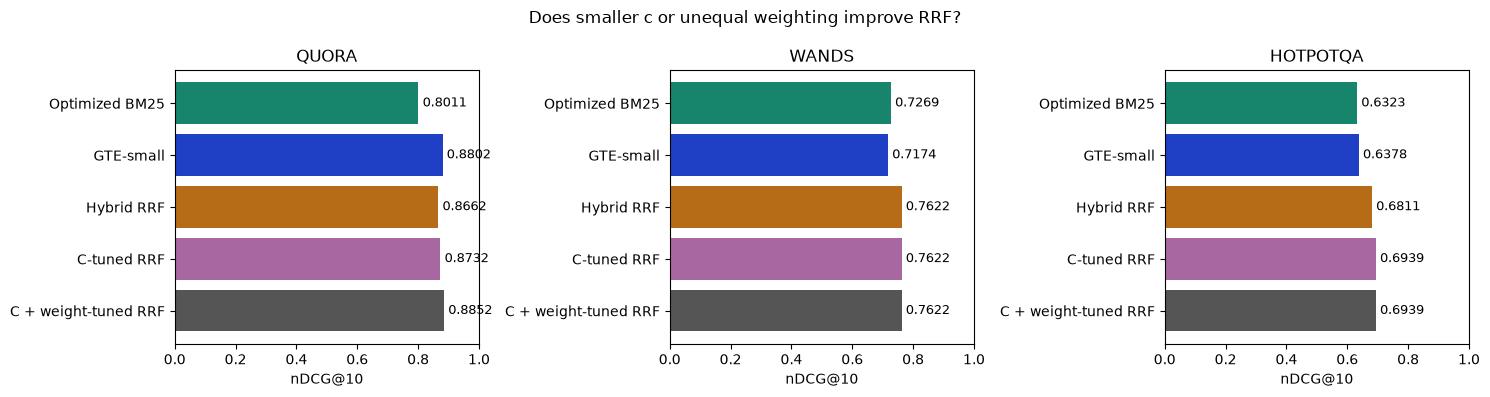

In [26]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5*len(DATASETS), 4), squeeze=False)
for ax, name in zip(axes[0], DATASETS):
    table = fusion_results[name]['summary']
    ax.barh(table['method'], table['nDCG@10'], color=['#16856b', '#1f3fc4', '#b66b16', '#a967a1', '#555555'])
    ax.invert_yaxis()
    ax.set(title=name.upper(), xlabel='nDCG@10', xlim=(0, 1))
    ax.bar_label(ax.containers[0], fmt='%.4f', padding=3, fontsize=9)
fig.suptitle('Does smaller c or unequal weighting improve RRF?')
fig.tight_layout()
plt.show()
